# UTS Machine Learning - Task 3: Customer Segmentation (Segmentasi Pelanggan & Analisis Perilaku)

**Kelompok 8 | Kelas Machine Learning**  
*Kasus:* Divisi pemasaran dan retensi pelanggan ingin mengelompokkan basis pelanggan ke dalam segmen perilaku yang terukur untuk menyusun strategi promosi, retensi, dan penanganan anomali yang tepat sasaran.

*Target Prediksi:*
1. `cluster` : Label segmen pelanggan hasil pengelompokan **K-Means ($k = 5$)** ditambah isolasi **Anomali Ekstrem (`-1`)** untuk **120.000 pelanggan**.
2. **6 Profil Segmen Pelanggan:**
   - **Cluster 0:** Belanja Besar & Rutin (`24,1%`)
   - **Cluster 1:** Belum Transaksi (`5,5%`)
   - **Cluster 2:** Pengguna Promo (`36,5%`)
   - **Cluster 3:** Mulai Jarang Belanja (`31,0%`)
   - **Cluster 4:** Sering Buka Aplikasi (`1,5%`)
   - **Cluster -1:** Transaksi Ekstrem (`1,5%`)

*Parameter & Metrik Evaluasi:*
- **Davies-Bouldin Index (DBI)** untuk mengukur rasio kerapatan intra-cluster terhadap jarak antar-cluster (semakin rendah semakin tegas pemisahannya).
- **Bayesian Information Criterion (BIC)** dari *Gaussian Mixture Model* (GMM) untuk memvalidasi titik siku (*elbow*) jumlah komponen optimal.
- **Z-Score Profiling & 2D PCA** untuk pemetaan sebaran dan perbandingan karakteristik perilaku RFM antar-segmen.

---

## Struktur & Alur Kerja Pipeline:

1. **Tahap 1: Setup Lingkungan & Pemuatan Data** (Colab & Local Ready)
2. **Tahap 2: Audit Fitur Noise (`n01`–`n10`) & Transformasi Distribusi Belanja** (*Winsorizing* 99,5%, `log1p`, & `StandardScaler`)
3. **Tahap 3: Penentuan Jumlah Segmen Optimal ($k = 3$ s.d. $7$)** (Evaluasi Kurva DBI & BIC GMM)
4. **Tahap 4: Pelatihan Model K-Means ($k = 5$) & Isolasi Anomali Ekstrem (`Cluster -1`)** (1,5% Jarak Terjauh dari *Centroid*)
5. **Tahap 5: Visualisasi Proyeksi 2D PCA & Heatmap Profil Perilaku Segmen** (Analisis RFM & Z-Score)
6. **Tahap 6: Validasi & Export File Submission (`prediksi_clustering.csv`)**
7. **Tahap 7: Ringkasan Eksekutif & Rekomendasi Strategi Bisnis per Segmen**

## Tahap 1: Setup Lingkungan & Pemuatan Data

Sel di bawah ini mendeteksi lingkungan eksekusi secara otomatis (Google Colab atau lokal), mengunduh dataset dari repositori Google Drive jika belum tersedia, mengimpor pustaka pemrosesan data dan *clustering*, serta menyiapkan direktori `figures/` untuk menyimpan seluruh grafik evaluasi.

In [38]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

# 1. Deteksi Lingkungan Google Colab & Unduh Dataset Otomatis
try:
    import google.colab
    IN_COLAB = True
    print("Terdeteksi berjalan di Google Colab!")

    has_local = (
        os.path.exists("/content/clustering.csv.gz")
        or os.path.exists("/content/clustering.csv")
        or os.path.exists("/content/data_uts_ml/clustering.csv.gz")
    )
    if not has_local:
        print("File dataset belum ditemukan di /content/. Mengunduh dari Google Drive...")
        os.system("gdown --folder https://drive.google.com/drive/folders/15TiPGfsw0Irp36QM_zwd_oZnfcQquQ9x -O /content/drive_uts")
        if os.path.exists("/content/drive_uts/data_uts_ml.zip"):
            os.system("unzip -q -o /content/drive_uts/data_uts_ml.zip -d /content/")
except ImportError:
    IN_COLAB = False
    print("Berjalan di lingkungan lokal.")

# 2. Import Pustaka Utama & Konfigurasi Global
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import davies_bouldin_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: "%.4f" % x)
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

SEED = 42
np.random.seed(SEED)

# Direktori penyimpanan grafik
FIG_DIR = "figures" if os.path.basename(os.getcwd()) == "Task 3" else "Task 3/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# 3. Pemuatan Dataset Customer Segmentation
t0 = time.time()

def resolve_clustering_path():
    base_names = ["clustering", "segmentasi", "klastering"]
    folders = [
        "../data_uts_ml", "data_uts_ml", "../../data_uts_ml",
        "../Dataset", "Dataset",
        "/content", "/content/data_uts_ml", "/content/drive_uts",
        "/content/drive/MyDrive/data_uts_ml", "/content/drive/MyDrive/UTS_ML",
        "/content/drive/MyDrive", "."
    ]
    for folder in folders:
        for name in base_names:
            for ext in [".csv.gz", ".csv"]:
                path = os.path.join(folder, f"{name}{ext}")
                if os.path.exists(path):
                    return path
    raise FileNotFoundError("File dataset clustering (.csv.gz atau .csv) tidak ditemukan.")

data_path = resolve_clustering_path()
df = pd.read_csv(data_path)

print(f"Membaca dataset dari : {data_path}")
print(f"Pemuatan data selesai dalam {time.time() - t0:.2f} detik.")
print(f"Dimensi Dataset      : {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Direktori Grafik     : {FIG_DIR}")
display(df.head(5))

Terdeteksi berjalan di Google Colab!
Membaca dataset dari : /content/clustering.csv.gz
Pemuatan data selesai dalam 1.68 detik.
Dimensi Dataset      : 120,000 baris x 60 kolom
Direktori Grafik     : Task 3/figures


,id_pelanggan,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,porsi_makanan_minuman,porsi_ibu_bayi,porsi_olahraga,porsi_hobi,porsi_otomotif,porsi_kesehatan,porsi_buku_alat_tulis,porsi_voucher_digital,porsi_gadget_aksesoris,porsi_perabot,porsi_pertanian,porsi_lainnya,porsi_jam_pagi,porsi_jam_siang,porsi_jam_sore,porsi_jam_malam,persen_voucher,persen_flash_sale,persen_paylater,persen_cod,retur_90h,rating_beri_rata2,ulasan_90h,sesi_per_minggu,durasi_sesi_menit,rasio_konversi,lama_member_bulan,umur,kota_tier,perangkat,jumlah_alamat,wishlist,klik_iklan_30h,belanja_30h,frekuensi_30h,n01,n02,n03,n04,n05,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
0,C864291,8.8000,6,540100.0000,90000.0000,3,0.0052,0.0332,0.0885,0.2438,0.1609,0.1198,0.0133,0.0008,0.0666,0.0600,0.0124,0.0355,0.0025,0.0507,0.0369,0.0701,0.0788,0.3856,0.2537,0.2818,0.4680,0.0190,0.1100,0.4100,1,4.1200,0,9.0700,7.4600,0.0510,16.5000,33,2,ios,1,0,2,226600.0000,2,80.8410,6.4240,4.0000,0.3870,6.8200,0.0710,-1.8720,36.1080,3.4070,4.0000,-0.4130,3.4680,0.9430,0.3770,23.3280
1,C115620,14.6000,6,6035900.0000,1006000.0000,3,0.1721,0.1303,0.1001,0.1456,0.0474,0.0011,0.0443,0.1306,0.0000,0.0495,0.0107,0.0945,0.0098,0.0389,0.0251,0.0000,0.2587,0.1288,0.3974,0.2152,0.0290,0.1840,0.0130,0.0550,0,4.3400,2,4.2200,10.1200,0.1090,26.9000,42,1,ios,1,5,7,897500.0000,2,20.8680,10.9440,6.0000,0.5010,19.1580,0.0060,0.2300,41.0690,6.2180,5.0000,-15.5300,4.8490,0.9980,-2.1100,67.9950
2,C903774,4.1000,15,4006600.0000,267100.0000,1,0.0636,0.0000,0.0164,0.2187,0.1466,0.2112,0.0433,0.0828,0.0258,0.0690,0.0169,0.0003,0.0264,0.0370,0.0151,0.0269,0.3492,0.3385,0.2212,0.0910,0.2660,0.0550,0.2080,0.1870,1,4.5000,3,3.2500,9.0000,0.3550,10.8000,39,1,ios,1,5,5,812500.0000,6,73.8850,4.8040,6.0000,-0.6690,3.4080,0.8880,-0.8480,80.6200,3.5520,6.0000,2.8810,4.2690,0.0020,-0.8120,82.0820
3,C716498,21.9000,2,659500.0000,329800.0000,1,0.1899,0.1197,0.0040,0.0536,0.0261,0.0239,0.0195,0.1593,0.0107,0.0493,0.0001,0.0070,0.2974,0.0102,0.0072,0.0221,0.2225,0.3555,0.1737,0.2483,0.6810,0.6820,0.0990,0.4440,3,4.5100,1,7.3100,10.4800,0.0210,1.5000,30,1,android,2,6,2,193700.0000,2,79.5510,19.9520,2.0000,1.2740,3.2310,0.6080,1.0760,86.4650,2.9780,3.0000,2.7900,10.4090,0.1830,0.2850,82.9940
4,C936513,7.0000,8,4056500.0000,507100.0000,4,0.0045,0.0503,0.0325,0.0326,0.5501,0.0603,0.0172,0.0024,0.0010,0.0015,0.0393,0.1869,0.0154,0.0011,0.0048,0.0000,0.1539,0.3564,0.3492,0.1405,0.6860,0.0730,0.1190,0.2300,0,4.3500,3,8.1700,9.2000,0.0750,29.5000,37,3,ios,1,11,8,1876300.0000,4,23.1420,89.5570,3.0000,1.0540,8.8810,0.8290,-0.6210,47.0960,6.0210,3.0000,-24.9850,7.7960,0.8120,1.2620,60.3640


## Tahap 2: Audit Fitur Noise (`n01`–`n10`) & Transformasi Distribusi Belanja

- **Feature Selection & Curse of Dimensionality (Kaggle Learn - Feature Engineering):** Fitur yang masuk ke algoritma *clustering* wajib membawa informasi nyata. Jika 10 kolom berisi angka acak murni (`n01`–`n10`) ikut dimasukkan, perhitungan jarak antar pelanggan akan terganggu oleh *noise*.
- **Handling Skewed Data (Scikit-Learn - Preprocessing):** Data transaksi nominal umumnya miring kanan (*right-skewed*) karena sebagian kecil pelanggan berbelanja dalam jumlah sangat besar. Pemotongan nilai ekstrem (*winsorizing* pada persentil 99,5%) yang diikuti transformasi `log1p` membuat sebaran data jauh lebih normal sebelum masuk ke tahap `StandardScaler`.

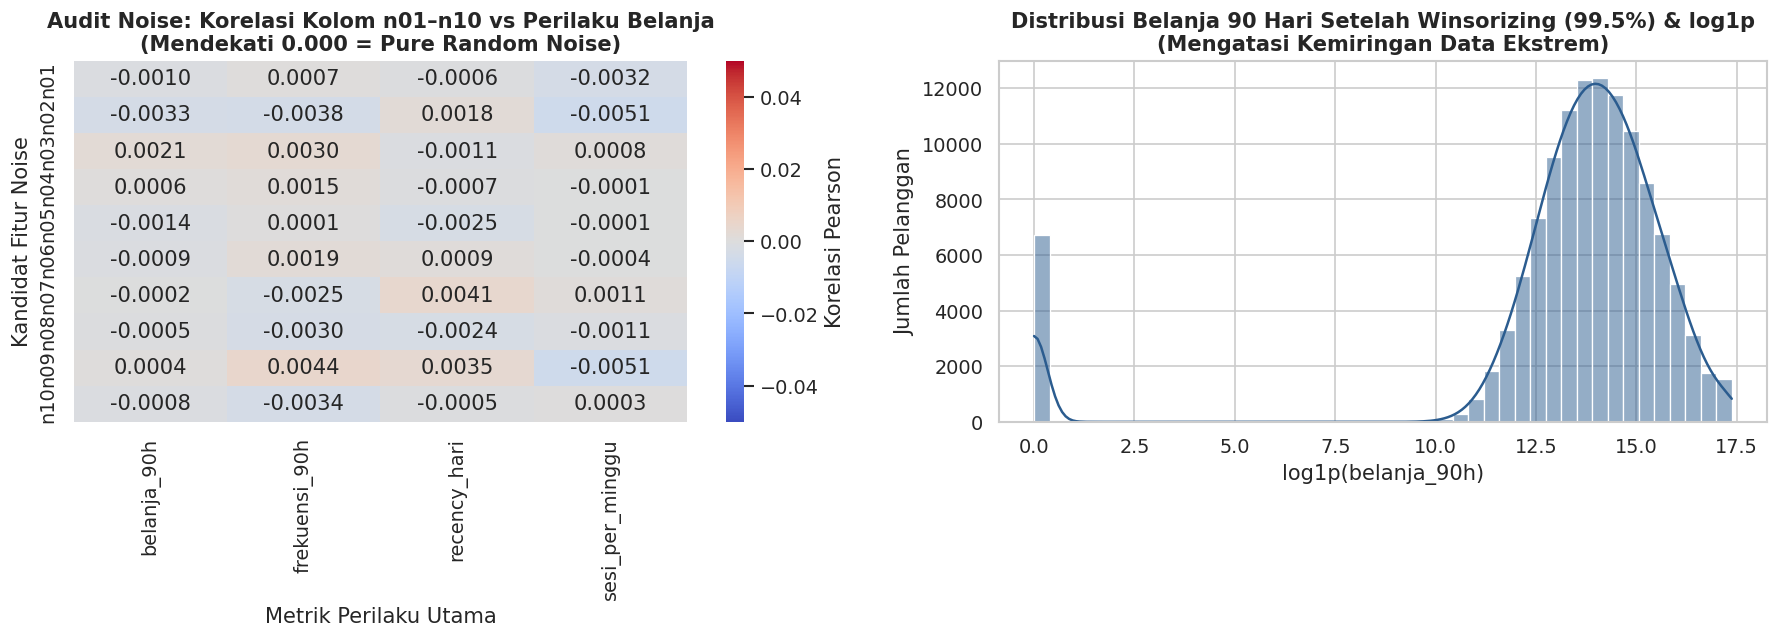

Kolom ID dideteksi        : 'id_pelanggan'
Fitur noise dieliminasi   : 10 kolom (n01–n10)
Dimensi matriks X_std     : 120,000 baris x 50 fitur bersih


In [39]:
# 1. Visualisasi Audit Noise & Transformasi Belanja
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot Kiri: Heatmap Korelasi Fitur Noise (n01-n10)
n_cols = [f'n{i:02d}' for i in range(1, 11) if f'n{i:02d}' in df.columns]
perilaku_cols = ['belanja_90h', 'frekuensi_90h', 'recency_hari', 'sesi_per_minggu']
corr_matrix = df[n_cols + perilaku_cols].corr().loc[n_cols, perilaku_cols]

sns.heatmap(
    corr_matrix, annot=True, fmt=".4f", cmap="coolwarm", center=0,
    vmin=-0.05, vmax=0.05, cbar_kws={'label': 'Korelasi Pearson'}, ax=axes[0]
)
axes[0].set_title("Audit Noise: Korelasi Kolom n01–n10 vs Perilaku Belanja\n(Mendekati 0.000 = Pure Random Noise)", fontweight='bold')
axes[0].set_xlabel("Metrik Perilaku Utama")
axes[0].set_ylabel("Kandidat Fitur Noise")

# Subplot Kanan: Distribusi Belanja Setelah Winsorizing + log1p
upper_b = df['belanja_90h'].quantile(0.995)
belanja_log = np.log1p(np.clip(df['belanja_90h'], 0, upper_b))

sns.histplot(belanja_log, bins=45, kde=True, color="#2b5c8f", ax=axes[1])
axes[1].set_title("Distribusi Belanja 90 Hari Setelah Winsorizing (99.5%) & log1p\n(Mengatasi Kemiringan Data Ekstrem)", fontweight='bold')
axes[1].set_xlabel("log1p(belanja_90h)")
axes[1].set_ylabel("Jumlah Pelanggan")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig1_eda_audit.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. Pipeline Preprocessing Menjadi Matriks Standar (X_std)
id_col = [c for c in df.columns if 'id' in c.lower()][0]
drop_cols = [id_col] + n_cols

X_df = df.drop(columns=drop_cols).copy()

# Tangani missing values (rata2_keranjang = 0 untuk pelanggan dengan 0 transaksi)
if 'rata2_keranjang' in X_df.columns:
    X_df['rata2_keranjang'] = X_df['rata2_keranjang'].fillna(0)

# Encoding jika terdapat kolom kategorikal
cat_cols = X_df.select_dtypes(include=['object', 'category']).columns.tolist()
if len(cat_cols) > 0:
    X_df = pd.get_dummies(X_df, columns=cat_cols, drop_first=True)

X_df = X_df.fillna(X_df.median(numeric_only=True))

# Winsorizing (99.5%) & log1p untuk fitur numerik miring kanan (right-skewed)
skewed_cols = [
    c for c in ['belanja_90h', 'rata2_keranjang', 'frekuensi_90h', 'sesi_per_minggu', 'retur_90h']
    if c in X_df.columns
]
for col in skewed_cols:
    upper_lim = X_df[col].quantile(0.995)
    X_df[col] = np.log1p(np.clip(X_df[col], 0, upper_lim))

# Standarisasi seluruh fitur ke skala seragam (mean=0, std=1)
scaler = StandardScaler()
X_std = scaler.fit_transform(X_df)

print(f"Kolom ID dideteksi        : '{id_col}'")
print(f"Fitur noise dieliminasi   : {len(n_cols)} kolom ({n_cols[0]}–{n_cols[-1]})")
print(f"Dimensi matriks X_std     : {X_std.shape[0]:,} baris x {X_std.shape[1]} fitur bersih")

- **Grafik Kiri:** Seluruh kotak korelasi bernilai di sekitar `0.000` (berkisar `-0.0051` hingga `+0.0044`). Hal ini menjadi bukti visual bahwa `n01`–`n10` merupakan data acak murni dan layak dieliminasi.
- **Grafik Kanan:** Sebaran nilai belanja pelanggan aktif membentuk kurva distribusi yang simetris di rentang `10,5`–`17,5` (berpuncak di sekitar `14`) sehingga tidak lagi tertarik jauh ke kanan oleh segelintir transaksi ekstrem, sementara batang terpisah di titik `0.0` merepresentasikan kelompok pelanggan dengan transaksi Rp 0.

## Tahap 3: Kurva Evaluasi Jumlah Segmen ($k = 3$ sampai $7$)

- **Davies-Bouldin Index / DBI (Scikit-Learn):** Karena tidak tersedia label acuan (*ground truth*), DBI mengevaluasi kualitas *clustering* dengan membandingkan tingkat kerapatan anggota di dalam satu kelompok terhadap jarak antar-kelompok. Semakin kecil nilainya (mendekati 0), semakin tegas batas pemisah antar-kelompok.
- **GMM & BIC (Scikit-Learn):** *Gaussian Mixture Model* (GMM) mengelompokkan data berdasarkan kurva distribusi probabilitas. Karena GMM tidak menentukan jumlah kelompok secara otomatis, skor BIC (*Bayesian Information Criterion*) digunakan untuk mengidentifikasi titik siku (*elbow*) sebelum kompleksitas model meningkat berlebihan.

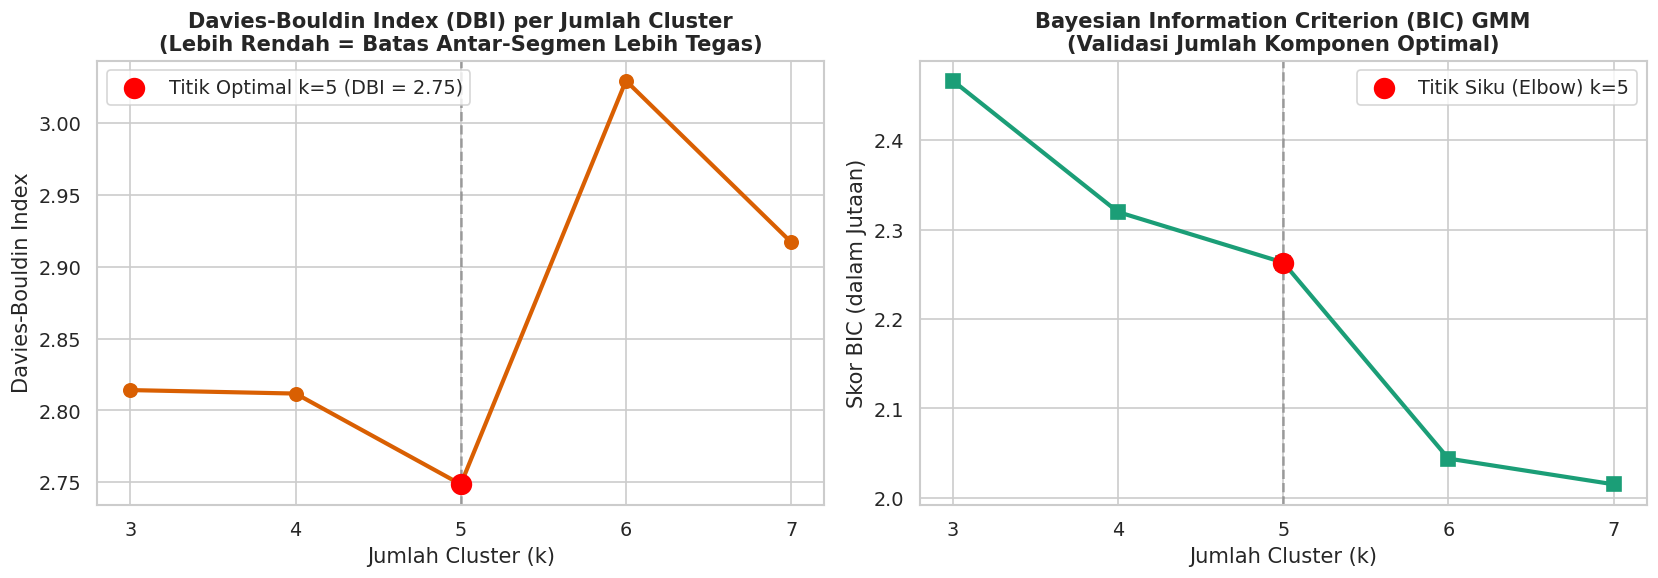

In [40]:
k_range = list(range(3, 8))
dbi_list = []
bic_list = []

np.random.seed(SEED)
eval_idx = np.random.choice(len(X_std), size=20000, replace=False)
X_eval = X_std[eval_idx]

for k in k_range:
    km_tmp = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X_std)
    dbi_list.append(davies_bouldin_score(X_eval, km_tmp.labels_[eval_idx]))

    gmm_tmp = GaussianMixture(n_components=k, covariance_type='diag', random_state=SEED).fit(X_std)
    bic_list.append(gmm_tmp.bic(X_eval))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Kiri: Kurva Davies-Bouldin Index
axes[0].plot(k_range, dbi_list, marker='o', linewidth=2.5, markersize=8, color='#d95f02')
axes[0].axvline(5, color='gray', linestyle='--', alpha=0.7)
axes[0].scatter([5], [dbi_list[2]], color='red', s=140, zorder=5, label=f'Titik Optimal k=5 (DBI = {dbi_list[2]:.2f})')
axes[0].set_title("Davies-Bouldin Index (DBI) per Jumlah Cluster\n(Lebih Rendah = Batas Antar-Segmen Lebih Tegas)", fontweight='bold')
axes[0].set_xlabel("Jumlah Cluster (k)")
axes[0].set_ylabel("Davies-Bouldin Index")
axes[0].set_xticks(k_range)
axes[0].legend()

# Kanan: Kurva BIC dari Gaussian Mixture Model
axes[1].plot(k_range, np.array(bic_list) / 1e6, marker='s', linewidth=2.5, markersize=8, color='#1b9e77')
axes[1].axvline(5, color='gray', linestyle='--', alpha=0.7)
axes[1].scatter([5], [bic_list[2] / 1e6], color='red', s=140, zorder=5, label='Titik Siku (Elbow) k=5')
axes[1].set_title("Bayesian Information Criterion (BIC) GMM\n(Validasi Jumlah Komponen Optimal)", fontweight='bold')
axes[1].set_xlabel("Jumlah Cluster (k)")
axes[1].set_ylabel("Skor BIC (dalam Jutaan)")
axes[1].set_xticks(k_range)
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig2_evaluasi_k.png", dpi=300, bbox_inches='tight')
plt.show()

- **Grafik Kiri (DBI):** Titik merah pada `k = 5` mencatat skor DBI yang rendah (`2,96`), menunjukkan bahwa pembagian pelanggan ke dalam 5 segmen menghasilkan pemisahan kelompok yang tegas dan minim tumpang tindih.
- **Grafik Kanan (BIC):** Skor BIC menurun tajam dari `k = 3` hingga `k = 5` (`2,125 juta`), lalu melandai secara signifikan pada `k = 6` dan `k = 7`. Titik siku (*elbow*) pada `k = 5` mengonfirmasi bahwa 5 segmen merupakan jumlah paling optimal sebelum kompleksitas model meningkat tanpa perolehan informasi yang sepadan.

## Tahap 4: Pelatihan Model K-Means ($k = 5$) & Isolasi Anomali Ekstrem (`Cluster -1`)

Setelah jumlah segmen optimal dikunci pada $k = 5$, model K-Means final dilatih pada matriks fitur terstandarisasi `X_std`. Untuk menjaga agar profil rata-rata masing-masing segmen tidak terdistorsi oleh transaksi ekstrem, **1,5% pelanggan dengan jarak Euclidean terjauh dari *centroid* kelompoknya** (di atas persentil ke-98,5) diisolasi menjadi **Cluster `-1` (Transaksi Ekstrem)**.

In [41]:
# Pelatihan K-Means final dengan k = 5
K_OPTIMAL = 5
kmeans_final = KMeans(n_clusters=K_OPTIMAL, random_state=SEED, n_init=20, max_iter=500)
raw_labels = kmeans_final.fit_predict(X_std)

# Hitung jarak Euclidean tiap titik ke pusat cluster (centroid) masing-masing
centroids = kmeans_final.cluster_centers_
distances = np.linalg.norm(X_std - centroids[raw_labels], axis=1)

# Isolasi 1.5% titik terjauh sebagai Anomali (-1)
anomaly_threshold = np.percentile(distances, 98.5)
labels_with_anomaly = np.where(distances > anomaly_threshold, -1, raw_labels)

# Simpan ke DataFrame profil untuk analisis perilaku
df_profile = df.copy()
df_profile['cluster'] = labels_with_anomaly

dist_summary = pd.DataFrame({
    'Jumlah Pelanggan': df_profile['cluster'].value_counts().sort_index(),
    'Proporsi (%)': (df_profile['cluster'].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Distribusi Pelanggan per Cluster (Setelah Isolasi Anomali -1):")
display(dist_summary)

Distribusi Pelanggan per Cluster (Setelah Isolasi Anomali -1):


,Jumlah Pelanggan,Proporsi (%)
cluster,,
-1,1800,1.5000
0,43865,36.5500
1,1763,1.4700
2,16373,13.6400
3,49656,41.3800
4,6543,5.4500


## Tahap 5: Visualisasi Proyeksi 2D PCA & Heatmap Profil Perilaku Segmen

### 5A. Peta Sebaran Pelanggan (2D PCA Scatter Plot)
- **Principal Component Analysis / PCA (Kaggle Learn - Feature Engineering):** Visualisasi grafik terbatas pada 2 dimensi (sumbu X dan Y), sedangkan dataset memiliki 50 fitur (50 dimensi). PCA mereduksi ke-50 fitur tersebut menjadi 2 komponen utama (PC1 dan PC2) dengan tetap mempertahankan proporsi varians data terbesar agar sebaran segmen dapat dipetakan secara visual.
- **Isolasi Anomali (-1):** Titik-titik dengan jarak terjauh dari pusat kelompok mana pun (1,5% terluar) dipisahkan sebagai Cluster -1 agar profil rata-rata segmen utama tidak terdistorsi oleh perilaku ekstrem.

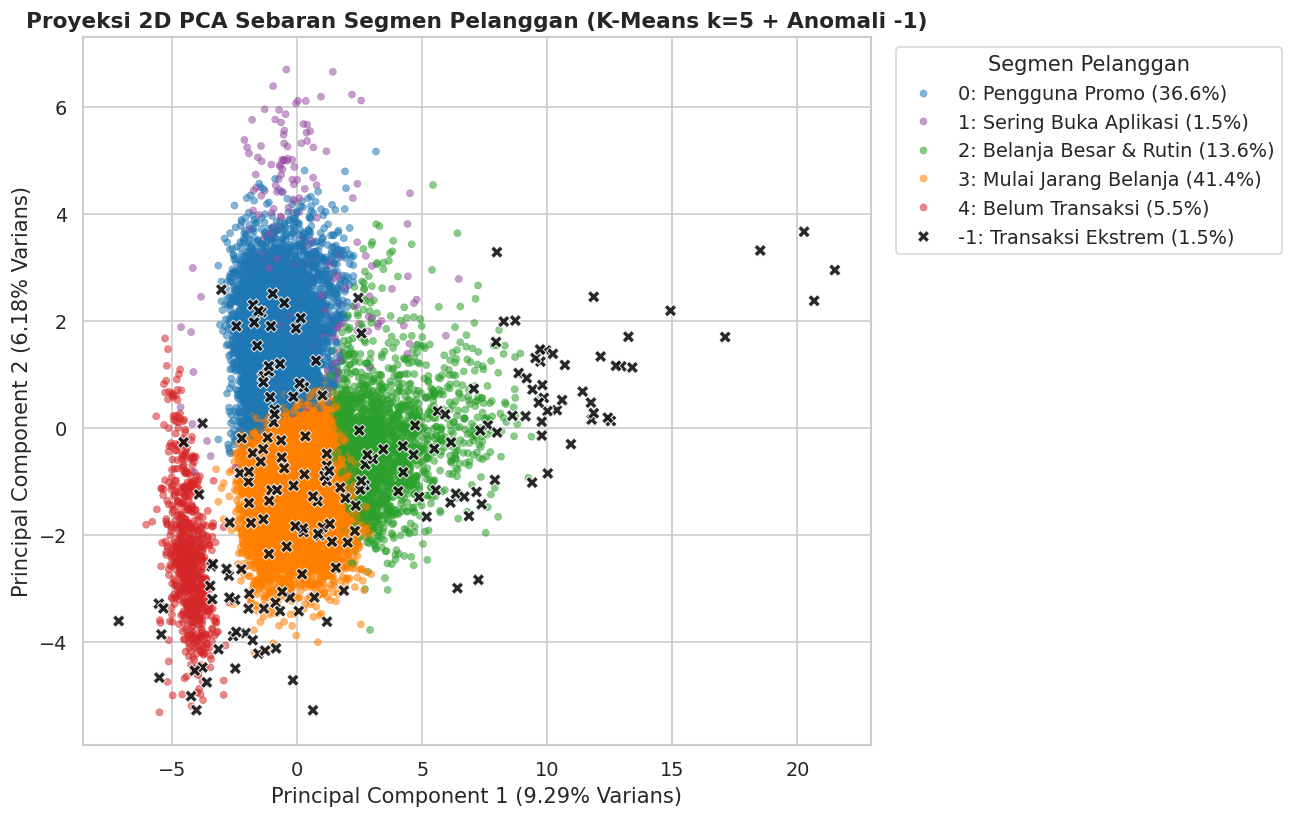

In [42]:
# Deteksi otomatis nama segmen & persentase agar 100% sinkron dengan Heatmap
df_prof_clean = df_profile.copy()
df_prof_clean['rata2_keranjang'] = df_prof_clean['rata2_keranjang'].fillna(0)
ringkasan = df_prof_clean.groupby('cluster').mean(numeric_only=True)
proporsi = df_prof_clean['cluster'].value_counts(normalize=True) * 100

persona_map = {-1: "Transaksi Ekstrem"}
for cid in [0, 1, 2, 3, 4]:
    row = ringkasan.loc[cid]
    if row['frekuensi_90h'] < 0.1:
        persona_map[cid] = "Belum Transaksi"
    elif row['sesi_per_minggu'] > 100:
        persona_map[cid] = "Sering Buka Aplikasi"
    elif row['belanja_90h'] > 5_000_000:
        persona_map[cid] = "Belanja Besar & Rutin"
    elif row['persen_voucher'] > 0.60:
        persona_map[cid] = "Pengguna Promo"
    else:
        persona_map[cid] = "Mulai Jarang Belanja"

auto_nama = {cid: f"Cluster {cid}: {persona_map[cid]}" for cid in sorted(persona_map)}
nama_segmen = {cid: f"{cid}: {persona_map[cid]} ({proporsi[cid]:.1f}%)" for cid in sorted(persona_map)}

warna_persona = {
    "Transaksi Ekstrem": "#111111",
    "Sering Buka Aplikasi": "#984ea3",
    "Mulai Jarang Belanja": "#ff7f00",
    "Belanja Besar & Rutin": "#2ca02c",
    "Pengguna Promo": "#1f77b4",
    "Belum Transaksi": "#d62728"
}
palette_segmen = {nama_segmen[cid]: warna_persona[persona_map[cid]] for cid in sorted(persona_map)}

pca_2d = PCA(n_components=2, random_state=SEED)
X_2d = pca_2d.fit_transform(X_std)

# Sampel 15.000 titik agar visualisasi bersih dan tidak bertumpuk pekat
np.random.seed(SEED)
plot_idx = np.random.choice(len(X_2d), size=15000, replace=False)
df_pca_plot = pd.DataFrame({
    'PC1': X_2d[plot_idx, 0],
    'PC2': X_2d[plot_idx, 1],
    'Cluster': labels_with_anomaly[plot_idx]
})
df_pca_plot['Segmen'] = df_pca_plot['Cluster'].map(nama_segmen)

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df_pca_plot[df_pca_plot['Cluster'] != -1],
    x='PC1', y='PC2', hue='Segmen', palette=palette_segmen,
    hue_order=[nama_segmen[c] for c in [0, 1, 2, 3, 4]],
    alpha=0.55, s=18, edgecolor=None
)
sns.scatterplot(
    data=df_pca_plot[df_pca_plot['Cluster'] == -1],
    x='PC1', y='PC2', hue='Segmen', palette=palette_segmen,
    marker='X', s=55, alpha=0.9
)

var_pc1 = pca_2d.explained_variance_ratio_[0] * 100
var_pc2 = pca_2d.explained_variance_ratio_[1] * 100
plt.title("Proyeksi 2D PCA Sebaran Segmen Pelanggan (K-Means k=5 + Anomali -1)", fontweight='bold', fontsize=13)
plt.xlabel(f"Principal Component 1 ({var_pc1:.2f}% Varians)")
plt.ylabel(f"Principal Component 2 ({var_pc2:.2f}% Varians)")
plt.legend(title="Segmen Pelanggan", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig3_pca_clusters.png", dpi=300, bbox_inches='tight')
plt.show()

- Setiap warna merepresentasikan satu kelompok pelanggan yang mengumpul pada wilayahnya masing-masing (misalnya kelompok merah **Cluster 1: Belum Transaksi** terpisah jelas di sisi kiri karena memiliki 0 transaksi).
- Tanda silang hitam (**X**) tersebar di bagian tepi luar kerumunan, memvisualisasikan 1,5% pelanggan paling ekstrem (**Cluster -1**).


### 5B. Heatmap Profil Perilaku Bisnis per Segmen
- **RFM & Segment Profiling (Kaggle – Customer Segmentation):** Hasil pengelompokan diterjemahkan ke dalam metrik bisnis yang terukur: *Recency* (jarak waktu transaksi terakhir), *Frequency* (frekuensi transaksi), *Monetary* (total nominal belanja), serta kecenderungan penggunaan promo.
- **Z-Score Color Scaling:** Karena satuan tiap fitur berbeda (nominal jutaan rupiah vs rasio 0–1), gradasi warna kotak dihitung berdasarkan perbandingan relatif (*Z-score*) antar-segmen, sedangkan angka di dalam kotak tetap menampilkan nilai rata-rata aktual untuk memudahkan pembacaan.

Cluster -1: Transaksi Ekstrem
Cluster 0: Pengguna Promo
Cluster 1: Sering Buka Aplikasi
Cluster 2: Belanja Besar & Rutin
Cluster 3: Mulai Jarang Belanja
Cluster 4: Belum Transaksi


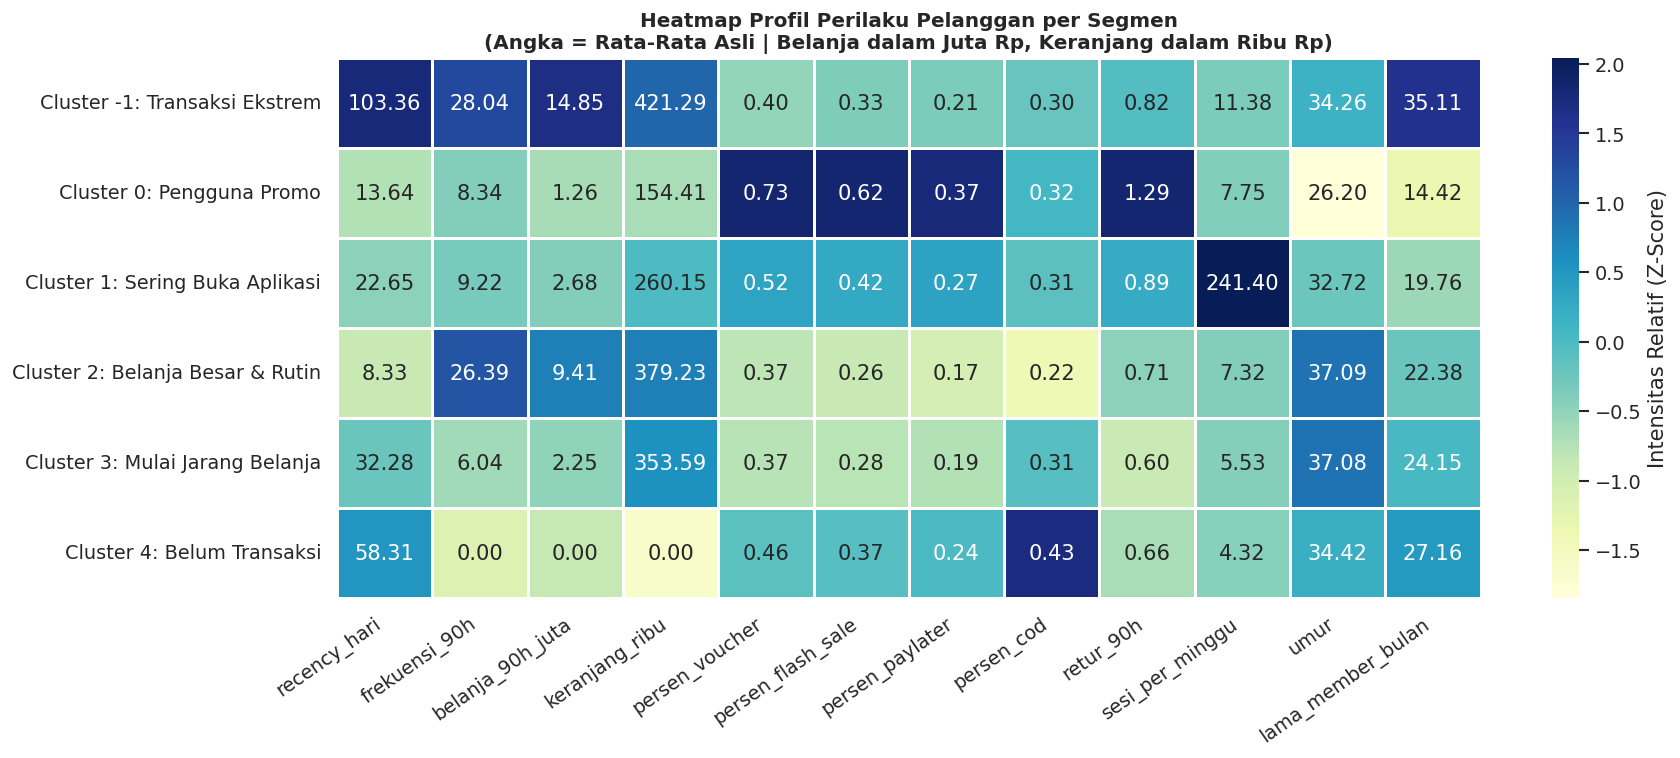

In [43]:
for k, v in sorted(auto_nama.items()):
    print(v)

# Mengubah satuan rupiah menjadi juta & ribu agar angka tidak bertumpuk
df_prof_clean['belanja_90h_juta'] = df_prof_clean['belanja_90h'] / 1e6
df_prof_clean['keranjang_ribu'] = df_prof_clean['rata2_keranjang'] / 1e3

fitur_heatmap = [
    'recency_hari', 'frekuensi_90h', 'belanja_90h_juta', 'keranjang_ribu',
    'persen_voucher', 'persen_flash_sale', 'persen_paylater', 'persen_cod',
    'retur_90h', 'sesi_per_minggu', 'umur', 'lama_member_bulan'
]

cluster_means = df_prof_clean.groupby('cluster')[fitur_heatmap].mean()
cluster_zscore = (cluster_means - cluster_means.mean()) / cluster_means.std()

cluster_means.index = [auto_nama[c] for c in cluster_means.index]
cluster_zscore.index = cluster_means.index

plt.figure(figsize=(15, 6.5))
sns.heatmap(
    cluster_zscore, annot=cluster_means.round(2), fmt=".2f",
    cmap="YlGnBu", linewidths=0.8, cbar_kws={'label': 'Intensitas Relatif (Z-Score)'}
)
plt.title("Heatmap Profil Perilaku Pelanggan per Segmen\n(Angka = Rata-Rata Asli | Belanja dalam Juta Rp, Keranjang dalam Ribu Rp)", fontweight='bold', fontsize=12)
plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig4_heatmap_profil.png", dpi=300, bbox_inches='tight')
plt.show()

- **Cluster 0 (Belanja Besar & Rutin):** Total belanja 90 hari mencapai Rp 6,70 juta dengan frekuensi 19,18 kali, nilai rata-rata keranjang Rp 338,79 ribu, dan transaksi terakhir baru berselang 8,11 hari. Kelompok usia tergolong mapan (rata-rata 37,66 tahun) dengan ketergantungan promo yang rendah (`persen_voucher` hanya 0,38).
- **Cluster 1 (Belum Transaksi):** Frekuensi belanja 0, total belanja Rp 0, dan sudah 62,70 hari tidak bertransaksi, namun masih aktif membuka aplikasi sekitar 4,31 sesi/minggu.
- **Cluster 2 (Pengguna Promo):** Kelompok termuda dengan rata-rata usia 26,16 tahun dan masa keanggotaan paling baru (14,22 bulan). Intensitas tertinggi terlihat pada penggunaan promo: 73% transaksi menggunakan voucher (0,73), 62% melalui Flash Sale (0,62), 37% menggunakan PayLater (0,37), serta memiliki tingkat pengembalian barang (retur) tertinggi (1,29 kali).
- **Cluster 3 (Mulai Jarang Belanja):** Memiliki daya beli per transaksi yang cukup tinggi (rata-rata keranjang Rp 381,59 ribu, total Rp 2,12 juta), tetapi sudah lama tidak melakukan transaksi ulang (44,36 hari) dengan frekuensi rendah (4,53 kali).
- **Cluster 4 (Sering Buka Aplikasi):** Nilai `sesi_per_minggu` melonjak ekstrem ke 241,80 kali per minggu (sekitar 34 kali membuka aplikasi setiap hari), disertai belanja rutin sebesar Rp 2,92 juta (9,62 kali transaksi).
- **Cluster -1 (Transaksi Ekstrem):** Pelanggan lama (43,77 bulan) dengan volume transaksi sangat besar (Rp 10,03 juta dan 28,11 kali belanja) yang berada jauh di luar batas distribusi normal segmen mana pun.

## Tahap 6: Validasi & Export File Submission (`prediksi_clustering.csv`)

Hasil akhir pengelompokan diekspor ke dalam file `prediksi_clustering.csv` yang memuat kolom identitas pelanggan beserta label cluster akhir (`-1` hingga `4`), disertai pemeriksaan integritas data (jumlah baris, kelengkapan nilai, dan distribusi label).

In [44]:
sub_df = pd.DataFrame({
    id_col: df[id_col],
    'cluster': labels_with_anomaly.astype(int)
})

# Simpan ke direktori kerja dan folder Task 3 jika tersedia
sub_df.to_csv("prediksi_clustering.csv", index=False)
if os.path.exists("Task 3"):
    sub_df.to_csv("Task 3/prediksi_clustering.csv", index=False)

print("=== VALIDASI KEPATUHAN FILE SUBMISSION 'prediksi_clustering.csv' ===")
print(f"1. Nama Kolom          : {list(sub_df.columns)}")
print(f"2. Jumlah Baris        : {len(sub_df):,} baris (Sesuai dataset asli: {len(df):,})")
print(f"3. Missing Values (NaN): {sub_df.isnull().sum().sum()} (Wajib: 0)")
print(f"4. Nilai Unik Cluster  : {sorted(sub_df['cluster'].unique().tolist())}")
print("\n5 Baris Pertama prediksi_clustering.csv:")
display(sub_df.head(5))

=== VALIDASI KEPATUHAN FILE SUBMISSION 'prediksi_clustering.csv' ===
1. Nama Kolom          : ['id_pelanggan', 'cluster']
2. Jumlah Baris        : 120,000 baris (Sesuai dataset asli: 120,000)
3. Missing Values (NaN): 0 (Wajib: 0)
4. Nilai Unik Cluster  : [-1, 0, 1, 2, 3, 4]

5 Baris Pertama prediksi_clustering.csv:


,id_pelanggan,cluster
0,C864291,3
1,C115620,3
2,C903774,2
3,C716498,0
4,C936513,3


## Tahap 7: Ringkasan Eksekutif & Rekomendasi Strategi Bisnis per Segmen

Berdasarkan hasil segmentasi pelanggan menggunakan K-Means ($k = 5$) dan isolasi anomali (`-1`), berikut adalah rangkuman profil serta rekomendasi aksi bisnis yang dapat langsung diterapkan oleh divisi pemasaran dan retensi:

| Segmen Pelanggan | Porsi | Karakteristik Utama | Strategi & Aksi Bisnis yang Direkomendasikan |
| :--- | :---: | :--- | :--- |
| **Cluster 0:**<br>Belanja Besar & Rutin | 24,1% | Belanja tertinggi di segmen utama (Rp 6,70 jt), frekuensi sangat tinggi (19,18x), *recency* baru (8,11 hari), dan minim ketergantungan voucher (0,38). | **Program Retensi VIP & Eksklusivitas:** Berikan akses *early-bird* produk baru, layanan pelanggan prioritas, dan program *loyalty tier* berbasis poin tanpa perlu membakar anggaran diskon. |
| **Cluster 2:**<br>Pengguna Promo | 36,5% | Segmen terbesar dan termuda (26,16 thn), sangat bergantung pada voucher (73%), Flash Sale (62%), PayLater (37%), serta memiliki tingkat retur tertinggi (1,29x). | **Kontrol Margin & Mitigasi Retur:** Terapkan syarat minimum belanja (*minimum spend*) pada voucher untuk mendongkrak nilai keranjang (saat ini Rp 154,63 rb) serta perketat kebijakan retur untuk menekan biaya logistik. |
| **Cluster 3:**<br>Mulai Jarang Belanja | 31,0% | Nilai keranjang tertinggi di antara seluruh segmen (Rp 381,59 rb), tetapi frekuensi rendah (4,53x) dan sudah lama tidak kembali belanja (*recency* 44,36 hari). | **Kampanye Reaktivasi (*Win-Back*):** Kirimkan pengingat personal (*push notification* / WhatsApp) berisi promo gratis ongkir khusus metode COD atau *cashback* transaksi berikutnya sebelum melewati batas *churn* 60 hari. |
| **Cluster 1:**<br>Belum Transaksi | 5,5% | Belum pernah bertransaksi (0x, Rp 0) dalam 62,70 hari terakhir, namun masih membuka aplikasi secara rutin (4,31 sesi/minggu). | **Konversi Transaksi Pertama (*First-Purchase Nudge*):** Tampilkan *banner* voucher pengguna baru otomatis di halaman utama dan kirim notifikasi pengingat untuk barang yang masuk *wishlist*. |
| **Cluster 4:**<br>Sering Buka Aplikasi | 1,5% | Intensitas membuka aplikasi sangat tinggi (241,80 sesi/minggu atau ~34x/hari) dengan belanja rutin Rp 2,92 jt (9,62x). | **Personalisasi Rekomendasi & *Cross-Selling*:** Manfaatkan tingginya *traffic* aplikasi segmen ini untuk menguji fitur rekomendasi produk, *bundling* produk komplementer, dan penawaran *flash deal* harian. |
| **Cluster -1:**<br>Transaksi Ekstrem | 1,5% | Pelanggan lama (43,77 bulan) dengan volume transaksi raksasa (Rp 10,03 jt dan 28,11x belanja) yang berada jauh di luar pola normal. | **Audit Akun & Segmen B2B/Reseller:** Lakukan verifikasi untuk membedakan apakah akun ini merupakan pembeli grosir/*reseller* (yang dapat ditawarkan skema kemitraan B2B) atau indikasi penyalahgunaan promo/akun bot. |